<a href="https://colab.research.google.com/github/Hassanat718/Well-Log-Data-Quality-Assessment-and-Visualization/blob/main/Well_Log_Data_Quality_Assessment_and_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Well-Log Data Quality Assessment and Visualization Using Python**

## **Project Objective**

This project focuses on inspecting and visualizing well-log data from the Niger Delta obtained during my training at Dharmattan Nigeria Limited. I will use Python to assess data quality, identify potential issues, and understand how they may affect subsequent petrophysical analysis.

## **Tools**

- Python
- pandas
- NumPy
- Matplotlib
- Plotly Express
- Google Colab

## **Workflow**

1. Inspect the raw data.
2. Assess data quality.
3. Investigate potential outliers and unusual measurements.
4. Visualize the well-log curves and their distributions.
5. Document observations, limitations, and conclusions.

### **Installing the Required Python Libraries**

Before starting the well-log data analysis, I need to ensure that the Python libraries required for this project are available in my working environment.

I will be using `lasio` to read and work with LAS files, which are commonly used to store well-log data. `pandas` and `NumPy` will help me organize, inspect, and process the data, while `Matplotlib` and `Plotly Express` will be used to create visualizations for examining log curves, understanding data distributions, and identifying possible data-quality issues. Plotly Express will also allow me to create interactive plots for exploring the data.

These libraries will provide the basic tools I need to work with the well-log data in Python.

### **Data Source and Disclaimer**

The well-log dataset used in this project was obtained during my training at Dharmattan Nigeria Limited, Lagos, where I received practical training in seismic interpretation and petrophysical evaluation. This notebook presents my personal work on well-log data quality assessment and visualization for learning and portfolio development purposes.

In [2]:
%pip install lasio pandas numpy matplotlib plotly

### **Importing the Required Libraries**

After installing the required libraries, I will import them into my Python environment so I can use their functions throughout this project.

I will use `lasio` to read the well-log data from the LAS file, `pandas` to organize the data into a table, and `NumPy` to support numerical operations. I will use `Matplotlib` to create static visualizations and `Plotly Express` to create interactive plots for examining the data distributions.

Importing these libraries at the beginning of the project will make them available for the subsequent data inspection, quality assessment, and visualization stages.

In [3]:
import lasio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

print("lasio version:", lasio.__version__)
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("\nAll required libraries imported successfully.")

lasio version: 0.32
pandas version: 2.2.3
NumPy version: 2.1.3

All required libraries imported successfully.


#### **Uploading the LAS File**

My well-log data is currently stored on my computer, so I need to upload the LAS file into the Google Colab environment before I can begin the analysis.

I will use Google Colab's file-upload function to select the file from my computer. Once uploaded, I will confirm the filename and use it to load the well-log data into Python.

At this stage, I am only uploading the file; I have not made any changes to the original well-log data.

In [4]:
from google.colab import files
uploaded = files.upload()

Saving Jay 01.LAS to Jay 01.LAS


### **Confirming the Uploaded File**

I will confirm the filename of the uploaded LAS file before loading it for inspection and analysis.

In [5]:
for filename in uploaded.keys():
    print("Uploaded file:", filename)

Uploaded file: Jay 01.LAS



##  **Data Source and Initial Validation**

Before performing well-log data quality assessment, the input file must be inspected to establish its structure and verify the available curve information.

This step checks the file format, available curve names, numerical data types, missing values, non-finite values, and the range of recorded measurements. Curve units and the null-value convention should be confirmed from the original file metadata or source documentation before further analysis.

These checks help distinguish potential data-quality issues from valid geological variations. No measurements will be removed or modified at this stage.


In [7]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the well-log data
file_path = Path("Jay 01.LAS")

if not file_path.exists():
    raise FileNotFoundError(
        "Jay 01.LAS was not found. Please upload the file "
        "or check its location."
    )

df = pd.read_csv(file_path, sep=r"\s+", engine="python")

# Inspect the dataset
print("=" * 50)
print("DATAFRAME VALIDATION")
print("=" * 50)

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNon-finite values:")
print(
    df.select_dtypes(include=np.number)
      .apply(lambda col: (~np.isfinite(col)).sum())
)

print("\nSummary statistics:")
print(df.describe().T)

DATAFRAME VALIDATION

Dataset shape:
(1380, 5)

Column names:
['MD', 'GR', 'NPHI', 'RES', 'RHOB']

Data types:
MD      float64
GR      float64
NPHI    float64
RES     float64
RHOB    float64
dtype: object

Missing values:
MD      0
GR      0
NPHI    0
RES     0
RHOB    0
dtype: int64

Non-finite values:
MD      0
GR      0
NPHI    0
RES     0
RHOB    0
dtype: int64

Summary statistics:
       count         mean         std          min         25%          50%  \
MD    1380.0  7104.750000  199.257999  6760.000000  6932.37500  7104.750000   
GR    1380.0    76.855557   40.712457    20.677999    35.59075    70.490002   
NPHI  1380.0     0.316299    0.093622     0.083400     0.26490     0.309200   
RES   1380.0   127.314071  361.483532     1.246000     2.48350     9.683000   
RHOB  1380.0     2.265742    0.151330     1.893000     2.15475     2.247500   

              75%          max  
MD    7277.125000  7449.500000  
GR     114.584499   199.613998  
NPHI     0.382150     0.489800  
RES 

# **OBSERVATION**
I first checked the original file to understand how the data is arranged and the well-log curves available. The file contains five columns: measured depth (MD), gamma ray (GR), neutron porosity (NPHI), resistivity (RES), and bulk density (RHOB).

The data is stored in a tab-separated format, without the usual LAS metadata sections. This means the curve units and null-value convention cannot be confirmed from the file itself, so they will need to be verified from the data source.

Before proceeding with the analysis, I will check the data types, missing values, non-finite values, and the range of values recorded for each curve to identify any potential data quality issues.

#### **Loading and Verifying the Well-Log Data**

The file could not be read using `lasio`, so I loaded it using `pandas` as a tab-separated text file. I will now check the dataset's structure, columns, and data types to confirm that the data has been read correctly before proceeding with cleaning and visualization.

In [ ]:
import pandas as pd
import io

# Since the file is actually a tab-separated tabular text file,
# we read it using pandas instead of lasio.
try:
    # Read the uploaded data directly from the uploaded dictionary
    df = pd.read_csv(io.BytesIO(uploaded['Jay 01.LAS']), sep='\t')
    print("File loaded successfully as a pandas DataFrame!")
    print("\nFirst few rows of the dataset:")
    print(df.head())
except Exception as e:
    print("Error loading file with pandas:", e)

File loaded successfully as a pandas DataFrame!

First few rows of the dataset:
       MD          GR    NPHI    RES   RHOB
0  6760.0  125.794998  0.3725  3.231  2.477
1  6760.5  124.441002  0.3688  3.134  2.478
2  6761.0  120.417000  0.3688  3.036  2.476
3  6761.5  117.928001  0.3744  2.942  2.471
4  6762.0  118.435997  0.3819  2.857  2.465


In [ ]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst five rows:")
display(df.head())
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset dimensions: (1380, 5)

Column names:
['MD', 'GR', 'NPHI', 'RES', 'RHOB']

Data types:
MD      float64
GR      float64
NPHI    float64
RES     float64
RHOB    float64
dtype: object

First five rows:


,MD,GR,NPHI,RES,RHOB
0,6760.0,125.794998,0.3725,3.231,2.477
1,6760.5,124.441002,0.3688,3.134,2.478
2,6761.0,120.417000,0.3688,3.036,2.476
3,6761.5,117.928001,0.3744,2.942,2.471
4,6762.0,118.435997,0.3819,2.857,2.465



Missing values per column:
MD      0
GR      0
NPHI    0
RES     0
RHOB    0
dtype: int64


### **Initial Data-Quality Checks**

The dataset contains measured depth and four well-log measurements. There are no missing values in the initial check. I will now check for duplicate depths and review the minimum and maximum values of each column to identify any potential data-quality issues before visualization.

In [ ]:
# Check for duplicate rows and measured depths
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate MD values:", df["MD"].duplicated().sum())
# Review the range and distribution of each column
display(df.describe().T)

Duplicate rows: 0
Duplicate MD values: 0


,count,mean,std,min,25%,50%,75%,max
MD,1380.0,7104.750000,199.257999,6760.000000,6932.37500,7104.750000,7277.125000,7449.500000
GR,1380.0,76.855557,40.712457,20.677999,35.59075,70.490002,114.584499,199.613998
NPHI,1380.0,0.316299,0.093622,0.083400,0.26490,0.309200,0.382150,0.489800
RES,1380.0,127.314071,361.483532,1.246000,2.48350,9.683000,39.049001,2000.000000
RHOB,1380.0,2.265742,0.151330,1.893000,2.15475,2.247500,2.421000,2.504000


**Observations**
- The dataset contains 1,380 rows and 5 columns: MD, GR, NPHI, RES, and RHOB.
- No missing values, duplicate rows, or duplicate measured depths were found.
- Measured depth ranges from 6,760 to 7,449.5 ft, with measurements taken at 0.5 ft intervals.
- Gamma Ray (GR) ranges from approximately 20.68 to 199.61 API.
- Neutron Porosity (NPHI) ranges from 0.0834 to 0.4898.
- Resistivity (RES) ranges from 1.246 to 2,000 ohm·m, showing a wide spread in values that requires further investigation.
- Bulk Density (RHOB) ranges from 1.893 to 2.504 g/cc.
These checks suggest that the dataset is complete and has no duplicate depth measurements.

However, the value ranges alone do not confirm that all measurements are valid. We need to visualize the log curves to identify unusual patterns or potential anomalies.

### **Data-Quality Checks**
Common null-value placeholders, such as `-999.25` and similar negative values, are checked as candidates rather than assumed to be the official null convention for this dataset. Unusual measurements are flagged for further investigation rather than automatically removed.

In [8]:
# Check for common candidate null-value sentinels
candidate_null_values = [-999.25, -999.0, -999.99, -9999.0]

print("\nCandidate null-value checks:")
for value in candidate_null_values:
    count = df.isin([value]).sum()
    if count.sum() > 0:
        print(f"{value}:")
        print(count[count > 0])
    else:
        print(f"{value}: not found")


Candidate null-value checks:
-999.25: not found
-999.0: not found
-999.99: not found
-9999.0: not found


### **Physical Plausibility Checks**

The log curves are checked for values that may be physically suspicious or outside the selected screening ranges. These checks include negative gamma-ray (GR) and neutron porosity (NPHI) values, NPHI values above 0.6, non-positive resistivity (RES), and bulk density (RHOB) values outside the selected range of 1.65–2.65 g/cc.

These limits are used to flag values for further investigation; they do not automatically indicate errors. Unusual values will be reviewed before deciding whether any data cleaning is necessary.

In [11]:
print("\nPhysical plausibility checks:")

checks = {
    "Negative GR": df["GR"] < 0,
    "Negative NPHI": df["NPHI"] < 0,
    "NPHI above 0.6": df["NPHI"] > 0.6,
    "Non-positive RES": df["RES"] <= 0,
    "RHOB below 1.65 g/cc": df["RHOB"] < 1.65,
    "RHOB above 2.65 g/cc": df["RHOB"] > 2.65
}

for label, condition in checks.items():
    print(f"{label}: {condition.sum()}")


Physical plausibility checks:
Negative GR: 0
Negative NPHI: 0
NPHI above 0.6: 0
Non-positive RES: 0
RHOB below 1.65 g/cc: 0
RHOB above 2.65 g/cc: 0


### **Measured-Depth Interval Check**

The measured-depth (MD) values are examined to verify the spacing between consecutive log samples. Consistent depth intervals help confirm the sampling pattern and identify any irregular gaps or unexpected depth increments. The observed interval will be compared with the expected 0.5 ft spacing before proceeding with further analysis.

In [10]:
# Check measured-depth intervals
md_intervals = df["MD"].diff().dropna()

print("Minimum MD interval:", md_intervals.min(), "ft")
print("Maximum MD interval:", md_intervals.max(), "ft")
print("Unique MD intervals:", sorted(md_intervals.unique()))
print("Intervals different from 0.5 ft:", (md_intervals != 0.5).sum())

Minimum MD interval: 0.5 ft
Maximum MD interval: 0.5 ft
Unique MD intervals: [np.float64(0.5)]
Intervals different from 0.5 ft: 0


### **Distribution of Well-Log Measurements**

I will use histograms to examine the distribution of GR, RES, NPHI, and RHOB values and identify their patterns and spread.

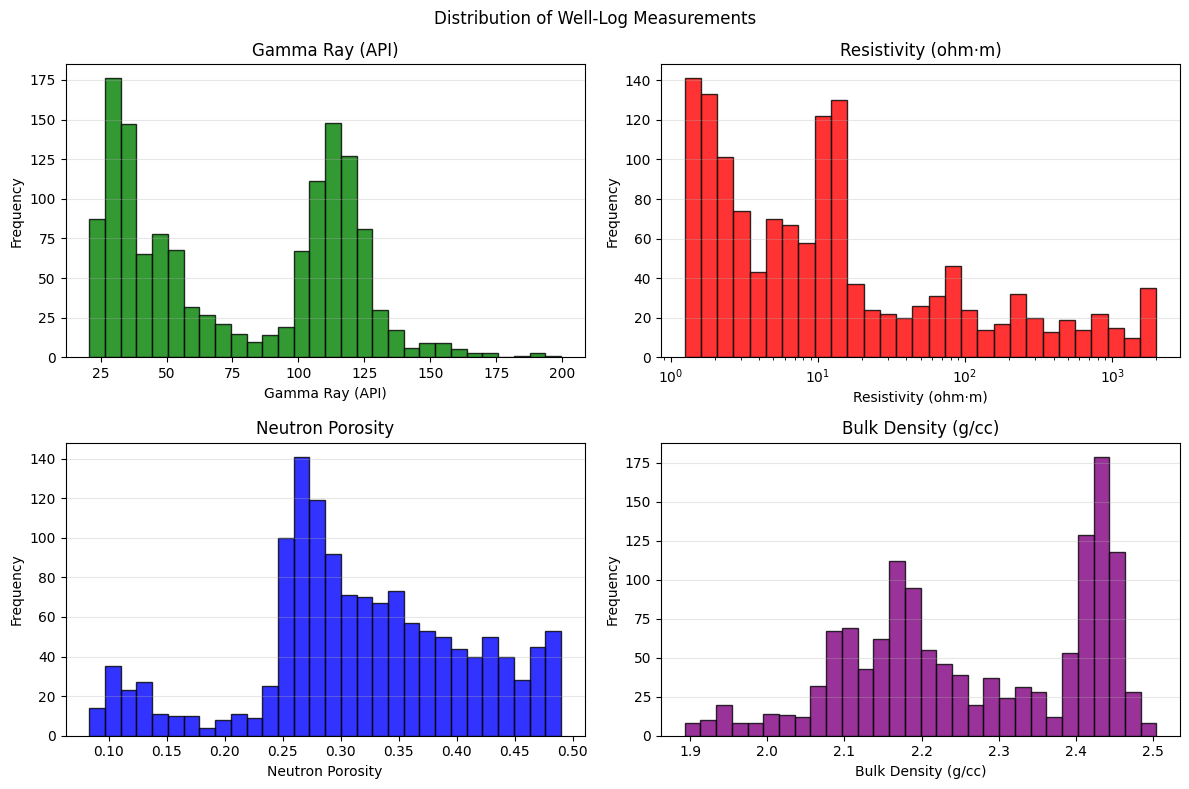

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the well-log curves and their display labels
logs = [
    ("GR", "Gamma Ray (API)"),
    ("RES", "Resistivity (ohm·m)"),
    ("NPHI", "Neutron Porosity"),
    ("RHOB", "Bulk Density (g/cc)")
]

# Assign consistent colours to match the well-log tracks
colors = {
    "GR": "green",
    "RES": "red",
    "NPHI": "blue",
    "RHOB": "purple"
}

# Create four histograms arranged in two rows and two columns
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Process each log curve and its corresponding subplot
for ax, (curve, label) in zip(axes.flatten(), logs):

    # Select the curve values and exclude missing data
    values = df[curve].dropna()

    if curve == "RES":
        # Keep only positive values because a logarithmic axis
        # cannot display zero or negative resistivity values
        positive_values = values[values > 0]

        # Create logarithmically spaced bins for resistivity
        bins = np.logspace(
            np.log10(positive_values.min()),
            np.log10(positive_values.max()),
            30
        )

        # Plot the resistivity histogram
        ax.hist(
            positive_values,
            bins=bins,
            color=colors[curve],
            edgecolor="black",
            alpha=0.8
        )

        # Display resistivity using a logarithmic x-axis
        ax.set_xscale("log")

    else:
        # Plot the other logs using a standard linear scale
        ax.hist(
            values,
            bins=30,
            color=colors[curve],
            edgecolor="black",
            alpha=0.8
        )

    # Add titles, axis labels, and horizontal gridlines
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

# Add an overall title and adjust the subplot spacing
plt.suptitle("Distribution of Well-Log Measurements")
plt.tight_layout()
plt.show()

### **Interactive Distribution of Well-Log Measurements**

I will also use Plotly Express to create interactive histograms of GR, RES, NPHI, and RHOB to examine the distribution and spread of each log curve. All four histograms will use a linear scale to display the original measurement values.

In [ ]:
import plotly.express as px

# Define the well-log curves, labels, and colours
logs = [
    ("GR", "Gamma Ray (API)", "green"),
    ("RES", "Resistivity (ohm·m)", "red"),
    ("NPHI", "Neutron Porosity (v/v)", "blue"),
    ("RHOB", "Bulk Density (g/cc)", "purple")
]

# Create an interactive histogram for each log curve
for curve, label, color in logs:

    # Select the curve and exclude missing values
    values = df[curve].dropna()

    # Create the histogram using a linear scale
    fig = px.histogram(
        x=values,
        nbins=30,
        title=f"{label} Histogram",
        labels={"x": label, "count": "Frequency"},
        color_discrete_sequence=[color]
    )

    # Add bar outlines
    fig.update_traces(
        marker_line_width=1,
        marker_line_color="white"
    )

    # Configure the chart layout
    fig.update_layout(
        xaxis_title=label,
        yaxis_title="Frequency",
        bargap=0.05
    )

    # Display the interactive histogram
    fig.show()

### **Initial Well-Log Visualization**

I started by plotting the log curves against measured depth to examine their variations with depth. In this initial plot, resistivity was displayed on a linear scale, making it difficult to appreciate variations across its wide range of values. The track arrangement, scale positioning and curve colours also needed improvement.

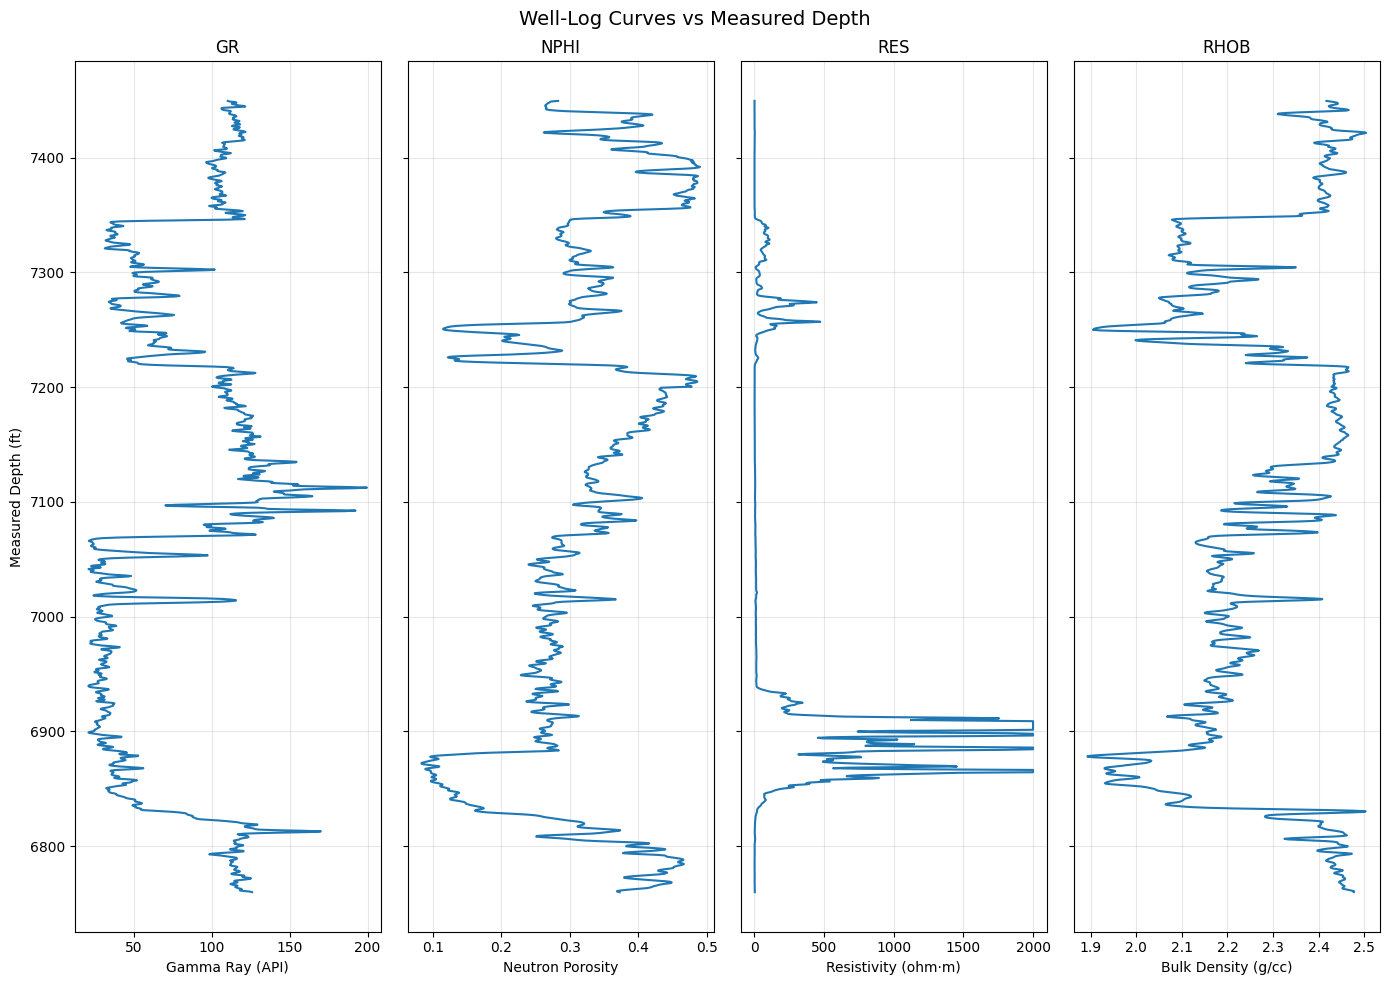

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 10), sharey=True)

logs = [
    ("GR", "Gamma Ray (API)"),
    ("NPHI", "Neutron Porosity"),
    ("RES", "Resistivity (ohm·m)"),
    ("RHOB", "Bulk Density (g/cc)")
]

for ax, (curve, label) in zip(axes, logs):
    ax.plot(df[curve], df["MD"])
    ax.set_xlabel(label)
    ax.set_title(curve)
    ax.grid(True, alpha=0.3)
    ax.invert_yaxis()

axes[0].set_ylabel("Measured Depth (ft)")
plt.suptitle("Well-Log Curves vs Measured Depth", fontsize=14)
plt.tight_layout()
plt.show()

### **Identifying Outliers in Resistivity (RES)**

From the well-log track above, the resistivity curve appears compressed because it is plotted on a linear scale. Since resistivity values span a wide range, I will plot it on a logarithmic scale to make the variations easier to examine. I will also compare a standard boxplot with a log-scaled boxplot to investigate potential outliers, including the maximum value of 2,000 ohm·m identified in the data summary.

# **Observation:**
The IQR method flagged 235 resistivity measurements as potential outliers, with a maximum value of 2,000 ohm·m. These values are not necessarily errors, as high resistivity can reflect genuine formation characteristics. I will retain the original values pending further investigation.

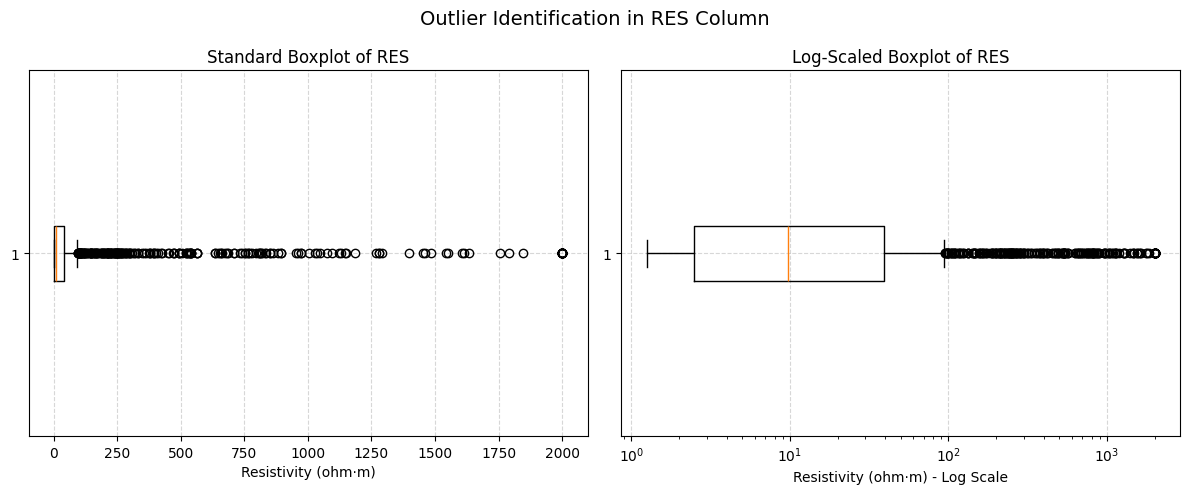

Q1 (25th percentile): 2.484 ohm·m
Q3 (75th percentile): 39.049 ohm·m
IQR: 36.566
Statistical outlier boundaries: Lower = -52.365, Upper = 93.897
Number of statistical outliers identified: 235 out of 1380 rows
Maximum outlier value: 2000.0 ohm·m


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Standard Boxplot
ax1.boxplot(df['RES'], vert=False)
ax1.set_title('Standard Boxplot of RES')
ax1.set_xlabel('Resistivity (ohm·m)')
ax1.grid(True, linestyle='--', alpha=0.5)

# Log-scaled Boxplot (helps visualize highly skewed petrophysical data)
ax2.boxplot(df['RES'], vert=False)
ax2.set_xscale('log')
ax2.set_title('Log-Scaled Boxplot of RES')
ax2.set_xlabel('Resistivity (ohm·m) - Log Scale')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Outlier Identification in RES Column', fontsize=14)
plt.tight_layout()
plt.show()

# Programmatically calculate Outliers using IQR
Q1 = df['RES'].quantile(0.25)
Q3 = df['RES'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['RES'] < lower_bound) | (df['RES'] > upper_bound)]

print(f"Q1 (25th percentile): {Q1:.3f} ohm·m")
print(f"Q3 (75th percentile): {Q3:.3f} ohm·m")
print(f"IQR: {IQR:.3f}")
print(f"Statistical outlier boundaries: Lower = {lower_bound:.3f}, Upper = {upper_bound:.3f}")
print(f"Number of statistical outliers identified: {len(outliers)} out of {len(df)} rows")
if len(outliers) > 0:
    print(f"Maximum outlier value: {outliers['RES'].max()} ohm·m")

### **Visualizing Resistivity on a Logarithmic Scale**

The initial well-log visualization showed that resistivity (RES) has a wide range of values. I have replotted RES on a logarithmic scale to make variations across this range easier to observe. This improves visualization without changing the original measurements.

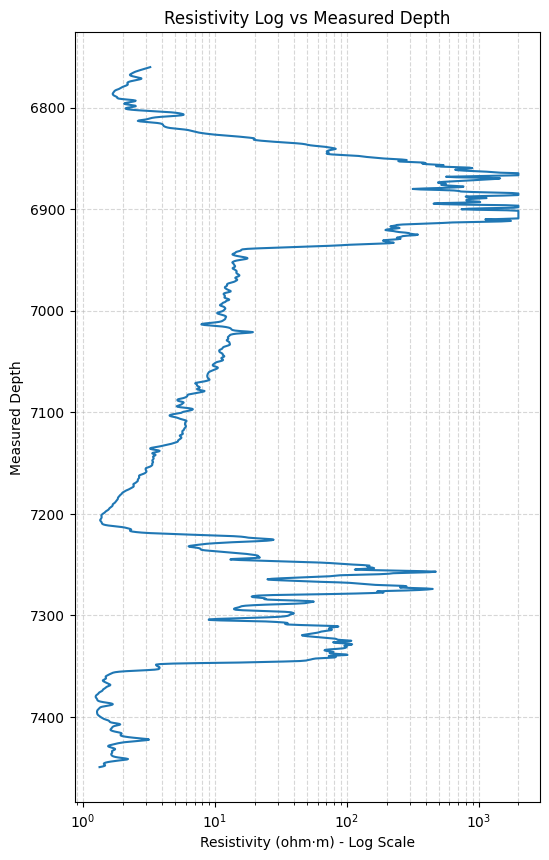

In [ ]:
plt.figure(figsize=(6, 10))

plt.plot(df["RES"], df["MD"])
plt.xscale("log")
plt.gca().invert_yaxis()

plt.xlabel("Resistivity (ohm·m) - Log Scale")
plt.ylabel("Measured Depth")
plt.title("Resistivity Log vs Measured Depth")
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.show()

### **Corrected Well-Log Visualization**

I made further adjustments by changing resistivity to a logarithmic scale, improving the track arrangement and repositioning the scales. I also placed RHOB and NPHI together for easier comparison and assigned colours to the log curves to improve readability.

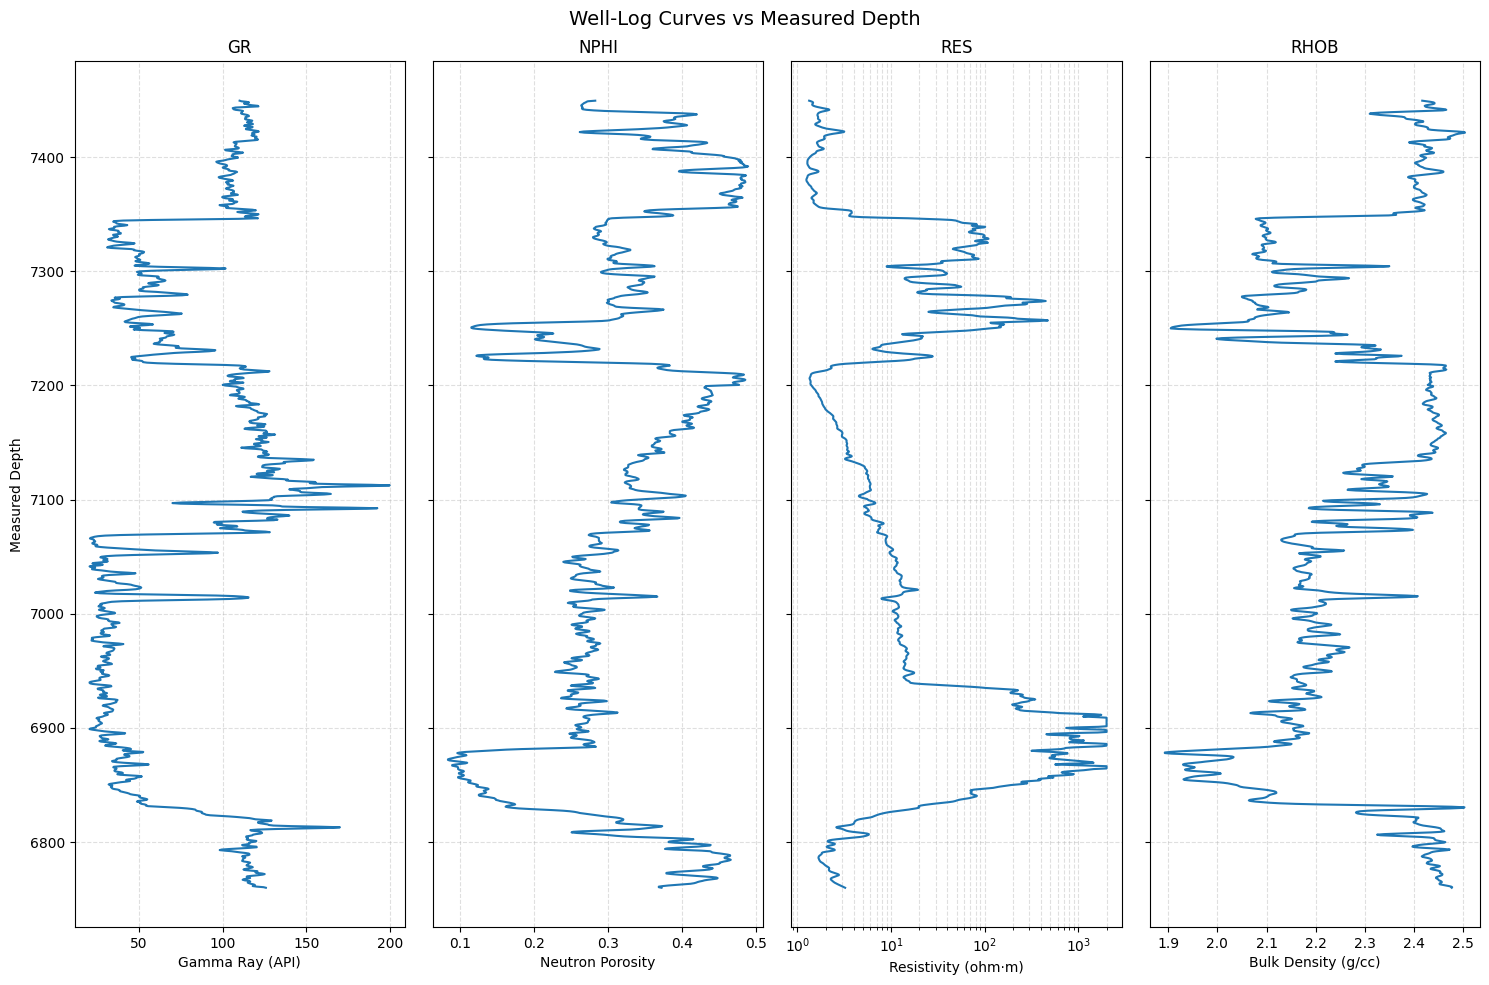

In [ ]:
import matplotlib.pyplot as plt

logs = [
    ("GR", "Gamma Ray (API)"),
    ("NPHI", "Neutron Porosity"),
    ("RES", "Resistivity (ohm·m)"),
    ("RHOB", "Bulk Density (g/cc)")
]

fig, axes = plt.subplots(1, 4, figsize=(15, 10), sharey=True)

for ax, (curve, label) in zip(axes, logs):
    ax.plot(df[curve], df["MD"])
    ax.set_xlabel(label)
    ax.set_title(curve)
    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    ax.invert_yaxis()

# Display resistivity on a logarithmic scale
axes[2].set_xscale("log")

axes[0].set_ylabel("Measured Depth")
plt.suptitle("Well-Log Curves vs Measured Depth", fontsize=14)
plt.tight_layout()
plt.show()

### **Standardized Well-Log Visualization**

In the final version, I further refined the track arrangement, standardized the scale positioning, maintained consistent curve colours and moved the depth scale to the top of the track. These improvements provide a clearer display for comparing log responses with depth and identifying intervals for further petrophysical evaluation.


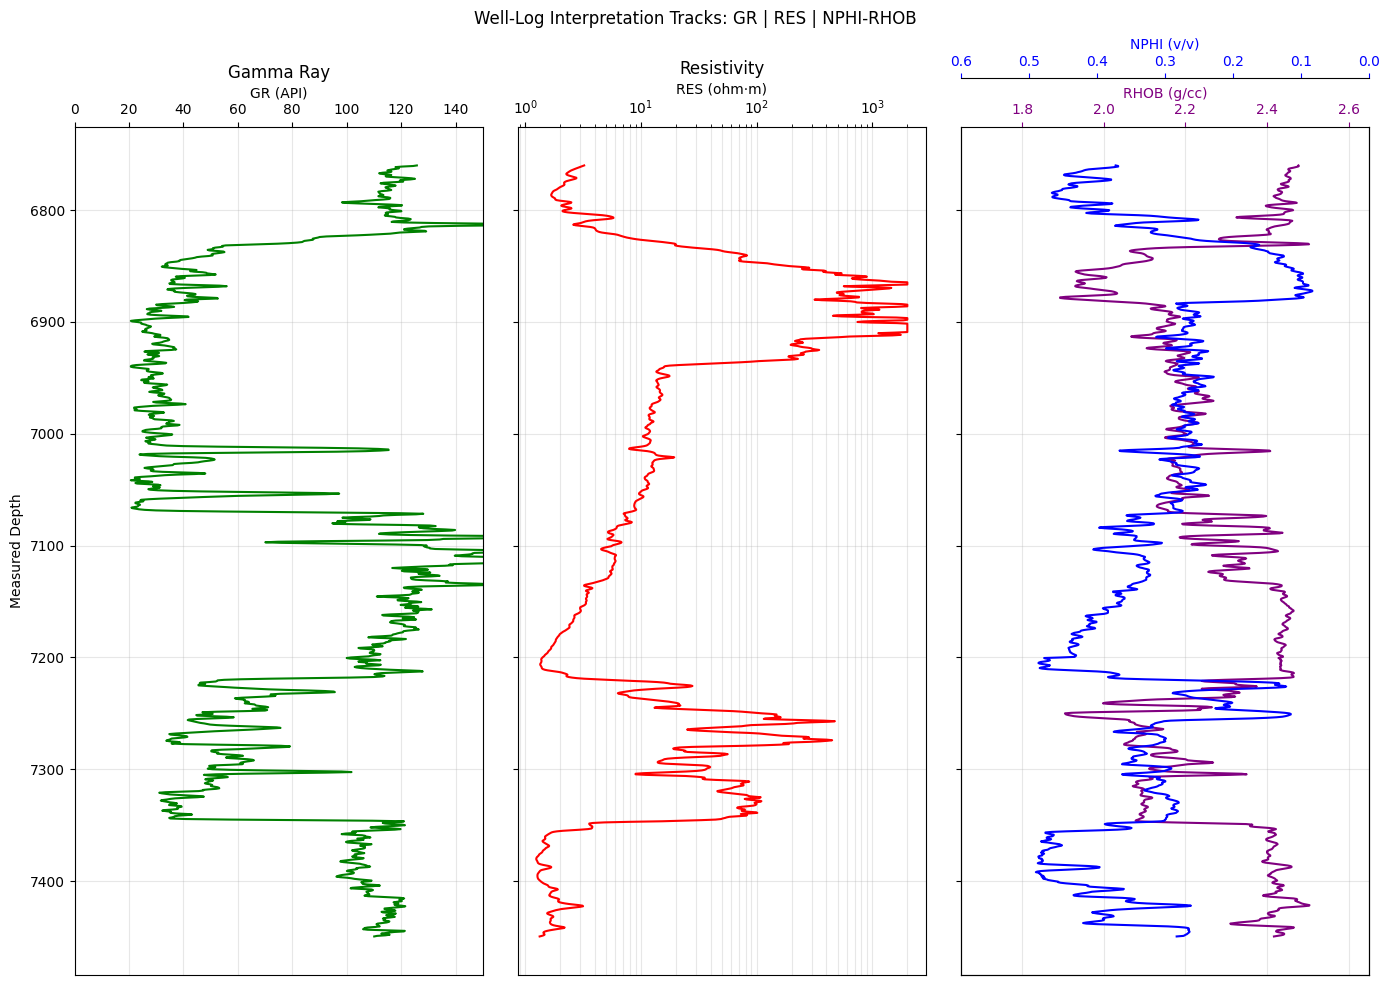

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 3, figsize=(14, 10), sharey=True
)

# Track 1: Gamma Ray (GR)
axes[0].plot(df["GR"], df["MD"], color="green")
axes[0].set_xlim(0, 150)
axes[0].set_xlabel("GR (API)")
axes[0].set_title("Gamma Ray")
axes[0].xaxis.set_label_position("top")
axes[0].xaxis.tick_top()

# Track 2: Resistivity (RES)
axes[1].plot(df["RES"], df["MD"], color="red")
axes[1].set_xscale("log")
axes[1].set_xlabel("RES (ohm·m)")
axes[1].set_title("Resistivity")
axes[1].xaxis.set_label_position("top")
axes[1].xaxis.tick_top()

# Track 3: NPHI and RHOB
ax_rhob = axes[2]
ax_nphi = ax_rhob.twiny()

ax_rhob.plot(df["RHOB"], df["MD"], color="purple")
ax_rhob.set_xlim(1.65, 2.65)
ax_rhob.set_xlabel("RHOB (g/cc)", color="purple")
ax_rhob.xaxis.set_label_position("top")
ax_rhob.xaxis.tick_top()
ax_rhob.tick_params(axis="x", colors="purple")

ax_nphi.plot(df["NPHI"], df["MD"], color="blue")
ax_nphi.set_xlim(0.6, 0)
ax_nphi.set_xlabel("NPHI (v/v)", color="blue")
ax_nphi.xaxis.set_label_position("top")
ax_nphi.xaxis.tick_top()
ax_nphi.spines["top"].set_position(("outward", 35))
ax_nphi.tick_params(axis="x", colors="blue")

# Formatting
for ax in axes:
    ax.invert_yaxis()
    ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel("Measured Depth")

plt.suptitle("Well-Log Interpretation Tracks: GR | RES | NPHI-RHOB")
plt.tight_layout()
plt.show()

### **Checking Well-Log Value Ranges**

I will check the minimum and maximum values of each log against the selected display ranges to identify values that may need further investigation.

In [ ]:
df[["GR", "RES", "NPHI", "RHOB"]].agg(["min", "max"]).T

,min,max
GR,20.677999,199.613998
RES,1.246000,2000.000000
NPHI,0.083400,0.489800
RHOB,1.893000,2.504000


### **Checking Values Outside Display Ranges**

I will identify measurements outside the selected display ranges to understand which values may be clipped in the plots and require further review.

In [ ]:
# Check values outside the selected display ranges
ranges = {
    "GR": (0, 150),
    "NPHI": (0, 0.6),
    "RHOB": (1.65, 2.65),
    "RES": (0, 2000)
}

for curve, (lower, upper) in ranges.items():
    outside = df[(df[curve] < lower) | (df[curve] > upper)]

    print(
        f"{curve}: {len(outside)} values outside "
        f"the display range {lower}–{upper}"
    )

GR: 26 values outside the display range 0–150
NPHI: 0 values outside the display range 0–0.6
RHOB: 0 values outside the display range 1.65–2.65
RES: 0 values outside the display range 0–2000


### **Gamma-Ray Values Above 150 API**
This section identifies and displays gamma-ray (GR) measurements exceeding the selected visualization limit of 150 API. These values are retained in the original dataset and are reviewed separately because they may represent high gamma-ray responses associated with shale-rich intervals or other geological or data-related factors.

In [13]:
# Identify GR values above 150 API
gr_above_150 = (
    df.loc[df["GR"] > 150, ["MD", "GR"]]
    .sort_values("MD")
)

print(f"Number of GR values above 150 API: {len(gr_above_150)}")

display(gr_above_150)

Number of GR values above 150 API: 26


,MD,GR
105,6812.5,166.020996
106,6813.0,169.940994
107,6813.5,158.212997
663,7091.5,161.395004
664,7092.0,185.457001
665,7092.5,192.233993
666,7093.0,175.317001
688,7104.0,152.621994
689,7104.5,160.576004
690,7105.0,164.528000


### **Interpretation of Display-Range Checks**

The display-range check identified 26 gamma-ray (GR) measurements above 150 API. These values may be hidden by the current GR plotting limit, although they remain in the dataset. No values were identified outside the selected display ranges for NPHI, RHOB, or RES.

The GR display range should therefore be reviewed to improve visualization while preserving all original measurements. Values will not be removed solely because they exceed the plotting limits.

### **Observation**

Twenty-six GR measurements exceed the selected display range of 0–150 API. In the Niger Delta, these elevated readings may indicate shale-rich intervals, while lower GR readings may suggest cleaner formations. However, these interpretations are preliminary, as GR responses can vary with mineral composition and local geology. The measurements will be retained because exceeding the selected display range does not necessarily indicate a data error.

### **Summary of Data Quality Assessment**

The dataset contains 1,380 rows and five columns, with no missing values, duplicate rows, or duplicate measured-depth (MD) values. The measured-depth interval was confirmed to be consistently spaced at 0.5 ft.

The physical plausibility checks identified no negative gamma-ray (GR) values, negative neutron porosity (NPHI) values, NPHI values above 0.6, non-positive resistivity (RES) values, or bulk-density (RHOB) values outside the selected range of 1.65–2.65 g/cc.

The RES outlier analysis identified potential statistical outliers, while the display-range check identified 26 GR measurements above 150 API. These measurements were retained because exceeding statistical or visualization limits does not necessarily indicate a data error. No measurements were removed or modified during the assessment.

# **Conclusion**

In this project, I used Python to inspect, assess, and visualize well-log data obtained during my training at Dharmattan Nigeria Limited. The dataset contained 1,380 rows and five columns: measured depth (MD), gamma ray (GR), neutron porosity (NPHI), resistivity (RES), and bulk density (RHOB).

The data-quality assessment included checks for missing values, duplicate records, duplicate measured-depth values, depth-sampling consistency, and potentially suspicious log measurements. No missing values or duplicates were found, and the measured-depth interval was confirmed to be consistently spaced at 0.5 ft.

I used Matplotlib and Plotly Express to examine log distributions and visualize the measurements. The RES analysis identified potential statistical outliers, while the GR display-range check identified 26 measurements above 150 API. These values were retained because there was insufficient evidence to classify them as errors.

Overall, this project strengthened my practical skills in Python-based well-log data inspection, quality assessment, and visualization. It also reinforced the importance of investigating unusual measurements before modifying or removing them, as they may represent genuine subsurface variations.

Further work could include investigating unusual log responses against depth and comparing them with geological information to support subsequent petrophysical evaluation.